# Tópico 17 - Relação entre Transformada-Z e DTFT

## Visão Geral e Objetivos
Neste notebook, investigamos a **Relação entre a Transformada-Z e a Transformada de Fourier em Tempo Discreto (DTFT)**. Os principais objetivos são:
1. **Mapeamento sobre o Círculo Unitário**: Demonstrar que, quando o círculo unitário ($|z| = 1$) pertence à Região de Convergência (ROC), a DTFT corresponde exatamente à avaliação da Transformada-Z ao longo do círculo unitário:
   $$X(e^{j\omega}) = \left. X(z) \right|_{z = e^{j\omega}}$$
2. **Influência dos Polos e Zeros na Resposta em Frequência**:
   - **Proximidade com Polos**: A aproximação de $z = e^{j\omega}$ a um polo provoca picos de amplificação na magnitude $|H(e^{j\omega})|$.
   - **Proximidade com Zeros**: A aproximação de $z = e^{j\omega}$ a um zero provoca atenuação ou nulos (*notches*) na magnitude $|H(e^{j\omega})|$.
3. **Simulação Geométrica e Espectral**: Plotar o mapa de polos e zeros no plano complexo $z$ lado a lado com a curva de resposta em frequência em magnitude e fase.
4. **Gerenciamento de Figuras**: Salvar os gráficos diretamente no diretório local de simulação.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Garantir a criação do diretório local para exportação das imagens
os.makedirs(".", exist_ok=True)

## 1. Definição do Sistema e Avaliação Analítica

Consideramos um sistema discreto LTI simples com:
- **Par de Polos Complexos Conjugados**: $p_{1,2} = 0.85 e^{\pm j \pi/4}$ (módulo $0.85$, ângulo $\omega = \pi/4 \approx 0.785\text{ rad/amostra}$).
- **Par de Zeros Complexos Conjugados**: $z_{1,2} = 0.9 e^{\pm j 3\pi/4}$ (módulo $0.9$, ângulo $\omega = 3\pi/4 \approx 2.356\text{ rad/amostra}$).

A função de transferência discreta é dada por:
$$H(z) = \frac{(z - 0.9 e^{j 3\pi/4})(z - 0.9 e^{-j 3\pi/4})}{(z - 0.85 e^{j \pi/4})(z - 0.85 e^{-j \pi/4})} = \frac{z^2 - 2(0.9)\cos(3\pi/4)z + 0.9^2}{z^2 - 2(0.85)\cos(\pi/4)z + 0.85^2}$$

Abaixo, definimos o sistema no SciPy e avaliamos sua resposta em frequência $H(e^{j\omega})$.

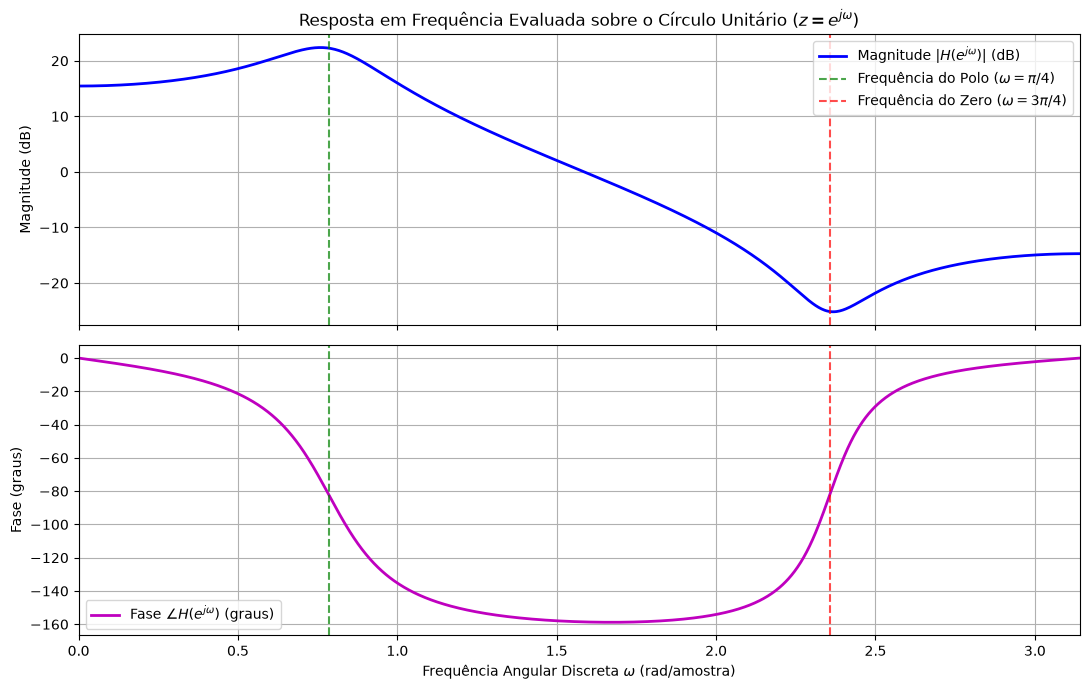

In [2]:
# Parâmetros dos polos e zeros
r_p, w_p = 0.85, np.pi / 4
r_z, w_z = 0.90, 3 * np.pi / 4

# Coeficientes do numerador (zeros) e denominador (polos)
b = [1.0, -2 * r_z * np.cos(w_z), r_z**2]
a = [1.0, -2 * r_p * np.cos(w_p), r_p**2]

sys = signal.dlti(b, a)

# Cálculo da resposta em frequência ao longo do círculo unitário z = exp(j*w)
w_rad, h_freq = signal.dfreqresp(sys, n=1000)

# Resposta em magnitude e fase
mag = np.abs(h_freq)
mag_db = 20 * np.log10(np.maximum(mag, 1e-4))
fase_rad = np.angle(h_freq)

# Plotagem da Resposta em Frequência (Magnitude e Fase)
fig1, (ax_mag, ax_fase) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

ax_mag.plot(w_rad, mag_db, 'b-', linewidth=2, label=r'Magnitude $|H(e^{j\omega})|$ (dB)')
ax_mag.axvline(w_p, color='g', linestyle='--', alpha=0.7, label=r'Frequência do Polo ($\omega = \pi/4$)')
ax_mag.axvline(w_z, color='r', linestyle='--', alpha=0.7, label=r'Frequência do Zero ($\omega = 3\pi/4$)')
ax_mag.set_title(r'Resposta em Frequência Evaluada sobre o Círculo Unitário ($z = e^{j\omega}$)')
ax_mag.set_ylabel('Magnitude (dB)')
ax_mag.grid(True)
ax_mag.legend(loc='upper right')

ax_fase.plot(w_rad, np.degrees(fase_rad), 'm-', linewidth=2, label=r'Fase $\angle H(e^{j\omega})$ (graus)')
ax_fase.axvline(w_p, color='g', linestyle='--', alpha=0.7)
ax_fase.axvline(w_z, color='r', linestyle='--', alpha=0.7)
ax_fase.set_xlabel(r'Frequência Angular Discreta $\omega$ (rad/amostra)')
ax_fase.set_ylabel('Fase (graus)')
ax_fase.set_xlim(0, np.pi)
ax_fase.grid(True)
ax_fase.legend(loc='lower left')

plt.tight_layout()
fig1.savefig("grafico_relacao_z_dtft_frequencia.png")
plt.show()

## 2. Interpretação Geométrica no Plano Complexo $z$

Plotamos o **Mapa de Polos e Zeros** juntamente com o **Círculo Unitário** para correlacionar geometricamente as distâncias aos polos e zeros com os picos e vales do espectro:
- O vetor que vai do polo $p_1 = 0.85 e^{j\pi/4}$ até a borda $z = e^{j\omega}$ atinge seu comprimento **mínimo** em $\omega = \pi/4$. Como o polo está no denominador, uma menor distância resulta em um **pico de magnitude**.
- O vetor que vai do zero $z_1 = 0.9 e^{j 3\pi/4}$ até a borda $z = e^{j\omega}$ atinge seu comprimento **mínimo** em $\omega = 3\pi/4$. Como o zero está no numerador, uma menor distância resulta em um **vale de atenuação (notch)**.

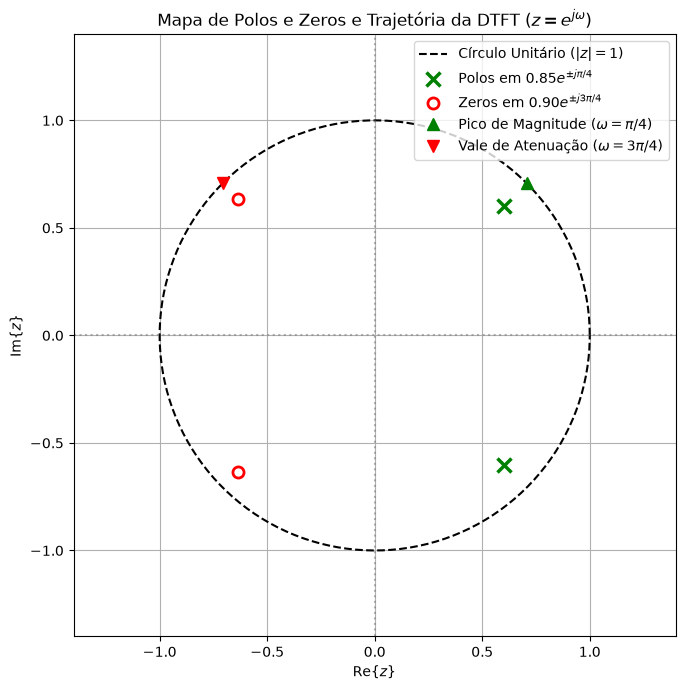

In [3]:
fig2, ax_pz = plt.subplots(figsize=(7, 7))

theta = np.linspace(0, 2 * np.pi, 300)
polos = sys.poles
zeros = sys.zeros

# Desenho do Círculo Unitário (|z| = 1)
ax_pz.plot(np.cos(theta), np.sin(theta), 'k--', linewidth=1.5, label='Círculo Unitário ($|z|=1$)')
ax_pz.axhline(0, color='gray', linestyle=':', alpha=0.6)
ax_pz.axvline(0, color='gray', linestyle=':', alpha=0.6)

# Plotar Polos (X) e Zeros (O)
ax_pz.plot(np.real(polos), np.imag(polos), 'gx', markersize=10, markeredgewidth=2.5, label=r'Polos em $0.85 e^{\pm j\pi/4}$')
ax_pz.plot(np.real(zeros), np.imag(zeros), 'ro', markersize=8, markerfacecolor='none', markeredgewidth=2, label=r'Zeros em $0.90 e^{\pm j 3\pi/4}$')

# Destacar os pontos de amostragem no círculo unitário correspondentes às frequências dos polos e zeros
ax_pz.plot(np.cos(w_p), np.sin(w_p), 'g^', markersize=9, label=r'Pico de Magnitude ($\omega = \pi/4$)')
ax_pz.plot(np.cos(w_z), np.sin(w_z), 'rv', markersize=9, label=r'Vale de Atenuação ($\omega = 3\pi/4$)')

ax_pz.set_title(r'Mapa de Polos e Zeros e Trajetória da DTFT ($z = e^{j\omega}$)')
ax_pz.set_xlabel(r'$\text{Re}\{z\}$')
ax_pz.set_ylabel(r'$\text{Im}\{z\}$')
ax_pz.set_xlim(-1.4, 1.4)
ax_pz.set_ylim(-1.4, 1.4)
ax_pz.set_aspect('equal')
ax_pz.grid(True)
ax_pz.legend(loc='upper right')

plt.tight_layout()
fig2.savefig("grafico_relacao_z_dtft_plano_z.png")
plt.show()

## 3. Síntese dos Resultados
- **Relação Fundamental**: A DTFT de um sinal ou a Resposta em Frequência de um sistema LTI discreto é exatamente a restrição da Transformada-Z ao longo do círculo unitário ($z = e^{j\omega}$), desde que o círculo unitário pertença à ROC.
- **Geometria de Polos e Zeros**:
  - Polos próximos ao círculo unitário elevam localmente a magnitude $|H(e^{j\omega})|$ (comportamento passa-faixa / ressonante).
  - Zeros próximos ou sobre o círculo unitário atenuam ou zera a magnitude $|H(e^{j\omega})|$ (comportamento rejeita-faixa / *notch*).